# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 제출 정보
- 이름: 유은송
- GitHub ID: song-03
- 작성일: 2026.11.02. 
- 최종 제출 URL: https://github.com/song-03/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 질문

### 분석 질문

1. completed 주문에서 카테고리별 주문 기준 금액, 판매 수량, 금액 비중은 어떻게 다른가?
2. completed 주문의 월별 주문 기준 금액, 고유 주문 수, 평균 주문 금액은 기간에 따라 어떻게 달라지는가?
3. completed 주문 기준 구매 금액이 높은 익명 고객은 주문 횟수와 평균 주문 금액에서 어떤 차이를 보이는가?

세 질문으로 범주 비교, 시간 변화, 고객별 구매 구조를 각각 확인한다. 결과를 서로 연결하려고 금액의 범위와 계산식을 공통으로 고정했고 질문마다 결과 표와 적절한 그래프를 함께 만든다.

### 질문별 정의

| 항목 | Q1. 카테고리 | Q2. 월별 | Q3. 익명 고객 |
| --- | --- | --- | --- |
| 분석 질문 | completed 주문에서 카테고리별 주문 기준 금액, 판매 수량, 금액 비중은 어떻게 다른가? | completed 주문의 월별 주문 기준 금액, 고유 주문 수, 평균 주문 금액은 기간에 따라 어떻게 달라지는가? | completed 주문 기준 구매 금액이 높은 익명 고객은 주문 횟수와 평균 주문 금액에서 어떤 차이를 보이는가? |
| 분석 대상 | completed 주문에 포함된 주문 상세와 상품 카테고리 | completed 주문과 해당 주문 상세 | completed 주문이 있는 고객(공개 시 순위 기반 익명 라벨) |
| 분석 범위 | `order_status == "completed"`, 2025-10~2026-10 | `order_status == "completed"`, 2025-10~2026-10 (시작/종료 월은 부분 기간 가능) | `order_status == "completed"`, 2025-10~2026-10 |
| 사용할 데이터 | `order_items.csv`, `orders.csv`, `products.csv` | `orders.csv`(`order_date` → `order_month`), `order_items.csv` | `customers.csv`, `orders.csv`, `order_items.csv` |
| 사용할 지표 | `total_quantity`, `total_sales`(= `line_total` 합계), `sales_ratio` | `total_sales`, `order_count`(고유 `order_id`), `avg_order_value` | `order_count`(고유 `order_id`), `total_sales`, `avg_order_value` |
| 결과 형태 | 카테고리 집계표 + 막대그래프 | 월별 집계표 + 선그래프 | 공개 고객 집계표 + 상위 10명 가로 막대그래프 |
| 완료 기준 | 카테고리 `total_sales` 합계가 completed source total과 차이 0원이고 `sales_ratio` 합계가 100.0%일 것 | 월별 `total_sales` 합계가 completed source total과 차이 0원이고 completed 주문 날짜 변환 오류가 0건일 것 | 고객 `total_sales` 합계가 completed source total과 차이 0원이고 공개 CSV에 원본 `customer_id`와 직접 식별 컬럼이 0개일 것 |

아래의 분석 범위, 데이터와 지표, 계산 기준, 완료 기준은 세 질문에 공통으로 적용된다.

### 분석 범위

- 금액성 분석 대상: `order_status == "completed"`인 주문과 해당 주문 상세
- 관찰 기간: 2025-10부터 2026-10까지
- 실행 후 확인된 범위: completed 주문 184건, 주문 상세 474행, 주문 기준 금액 합계 148,990,000원
- 예외 범위: 주문 상태 분포는 completed만 필터링하지 않고 전체 주문 300건을 사용
- 제외 범위: cancelled 64건과 refunded 52건은 상태 분포에는 포함하지만 completed 금액 분석에서는 제외

금액 분석과 상태 분포는 모집단이 달라서 각 표와 그래프의 제목에 범위를 명시한다. 시작 월과 종료 월은 한 달 전체가 아닐 가능성이 있으므로 월별 최저와 최고를 해석할 때 기간 길이 차이를 별도로 고려한다.

### 사용할 데이터와 지표

- `customers.csv`: 고객 연결과 익명 고객별 주문 횟수, 금액 집계
- `products.csv`: 상품과 카테고리 연결
- `orders.csv`: 주문일, 주문 상태, 고객 연결
- `order_items.csv`: 수량, 단가, 주문 상세 연결
- 금액 지표: `line_total = quantity × unit_price`
- 주문 수: 고유 `order_id` 개수(주문 상세 행 수로 세지 않음)
- 카테고리 지표: `total_quantity`, `total_sales`, `sales_ratio`
- 월별 지표: `total_sales`, `order_count`, `avg_order_value`
- 고객 지표: `order_count`, `total_sales`, `avg_order_value`
- 결과 형태: 카테고리 집계표와 막대그래프, 월별 집계표와 선그래프, 익명 고객 집계표와 가로 막대그래프

### 계산 기준

- `order_status == "completed"` 적용 여부: 적용함. 취소/환불 주문의 금액을 완료 주문 결과에 포함하지 않기 위해서다.
- `line_total = quantity × unit_price` 확인 여부: 전체 주문 상세 764행을 다시 계산해 저장값과 비교한다.
- 카테고리, 월, 고객 집계는 동일한 completed source에서 시작한다.
- 월별 주문 수와 고객별 주문 수는 고유 `order_id`로 계산한다.
- 공개 고객 결과는 원본 `customer_id`를 제거하고 금액 순위 기반 `Customer 01` 형식의 라벨을 사용한다.

전체 주문을 금액 분석에 사용하는 대안도 가능하지만 그러면 cancelled/refunded 주문 116건의 금액이 섞여 완료된 거래의 규모를 설명하기 어렵다. 이 때문에 completed 범위를 기본 계약으로 선택했다. 전체 주문은 상태 분포를 설명할 때만 사용한다.

### 완료 기준

- 네 데이터셋의 PK 결측/중복이 각각 0건이고 세 FK 미매칭이 0건일 것
- 예상한 병합 관계가 `validate`를 통과하고 병합 전후 행 수 변화와 미매칭이 각각 0건일 것
- 전체 764행의 `line_total` 불일치가 0건일 것
- category, month, customer 총합이 completed source total과 각각 일치하고 차이가 0원일 것
- completed 주문의 날짜 변환 오류가 0건이고 오류 영향 금액도 0원일 것
- 카테고리 비중 합계가 100.0%일 것
- 공개 고객 결과에 원본 ID와 직접 식별정보가 없을 것
- 대표 그래프가 원본 집계값과 일치하고 필수 CSV, PNG, Markdown 산출물이 생성될 것

### 기준 설정에 대한 판단

이 질문들은 “무엇이 큰가”를 찾은 뒤 같은 범위와 계산식으로 만든 결과인지까지 검증하도록 설계했다. 금액 순위만 보면 수량과 단가의 영향을 구분할 수 없고 월별 총금액만 보면 주문 수와 주문당 금액의 영향을 분리할 수 없어서 각 질문에 보조 지표를 함께 두었다. 완료 기준도 “잘 분석한다” 같은 주관적 표현 대신 0건, 0원, 100.0%, PASS처럼 재실행으로 확인 가능한 조건으로 정했다.

### 한계와 추가 확인 사항

질문을 사전에 구체화해도 현재 데이터에 없는 원가, 할인, 배송비, 프로모션, 만족도와 유입 경로는 분석할 수 없다. 그래서 completed 주문 기준 금액을 회계상 순매출이나 이익으로 부르지 않는다. 관찰된 차이도 선호도나 마케팅 효과의 원인으로 단정하지 않는다.

## 실행 단계 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-course
원본 데이터 폴더: C:\dev\llm-data-analysis-course\data\raw
보고서 폴더: C:\dev\llm-data-analysis-course\reports


## 실행 단계 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 실행 단계 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 실행 단계 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\order_items_clean.csv OK


In [5]:
column_changes = []
for name in raw_data:
    raw_df = raw_data[name]
    processed_df = processed_data[name]
    column_changes.append(dict(
        dataset=name,
        row_delta=len(processed_df) - len(raw_df),
        column_delta=len(processed_df.columns) - len(raw_df.columns),
        added_columns=[c for c in processed_df.columns if c not in raw_df.columns],
        removed_columns=[c for c in raw_df.columns if c not in processed_df.columns],
    ))

column_changes = pd.DataFrame(column_changes)
display(column_changes)


,dataset,row_delta,column_delta,added_columns,removed_columns
0,customers,0,0,[],[]
1,products,0,0,[],[]
2,orders,0,2,"[order_month, order_dayofweek]",[]
3,order_items,0,1,[line_total],[]


In [6]:
# 전처리 후 결측·중복·주요 타입·주요 ID 재검사
KEY_COLUMNS = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
}

post_checks = []
for name, df in processed_data.items():
    key = KEY_COLUMNS[name]
    post_checks.append(dict(
        dataset=name,
        rows=df.shape[0],
        columns=df.shape[1],
        missing_total=int(df.isna().sum().sum()),
        duplicated_rows=int(df.duplicated().sum()),
        key_column=key,
        key_missing=int(df[key].isna().sum()),
        key_duplicated=int(df[key].duplicated().sum()),
    ))

post_preprocessing_checks = pd.DataFrame(post_checks)
display(post_preprocessing_checks)

for name, df in processed_data.items():
    missing = df.isna().sum()
    print(f"\n[{name}] 컬럼:", df.columns.tolist())
    print("결측이 있는 컬럼:", missing[missing > 0].to_dict())
    print(df.dtypes.to_string())

assert post_preprocessing_checks["missing_total"].eq(0).all()
assert post_preprocessing_checks["duplicated_rows"].eq(0).all()
assert post_preprocessing_checks["key_missing"].eq(0).all()
assert post_preprocessing_checks["key_duplicated"].eq(0).all()
print("\n전처리 후 결측·중복·주요 ID 재검사: PASS")


,dataset,rows,columns,missing_total,duplicated_rows,key_column,key_missing,key_duplicated
0,customers,150,6,0,0,customer_id,0,0
1,products,100,4,0,0,product_id,0,0
2,orders,300,7,0,0,order_id,0,0
3,order_items,764,6,0,0,order_item_id,0,0



[customers] 컬럼: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
결측이 있는 컬럼: {}
customer_id             int64
name                      str
gender                    str
age                     int64
city                      str
signup_date    datetime64[us]

[products] 컬럼: ['product_id', 'product_name', 'category', 'price']
결측이 있는 컬럼: {}
product_id      int64
product_name      str
category          str
price           int64

[orders] 컬럼: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']
결측이 있는 컬럼: {}
order_id                    int64
customer_id                 int64
order_date         datetime64[us]
payment_method                str
order_status                  str
order_month                   str
order_dayofweek               str

[order_items] 컬럼: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']
결측이 있는 컬럼: {}
order_item_id    int64
order_id         int64
product_id      

## 2. 입력 데이터와 전처리 검증

- 사용 원본 파일: `customers.csv`, `products.csv`, `orders.csv`, `order_items.csv`
- shape:

| 데이터 | 원본 shape | 주요 키 |
| --- | ---: | --- |
| customers | 150행 × 6열 | `customer_id` |
| products | 100행 × 4열 | `product_id` |
| orders | 300행 × 5열 | `order_id` |
| order_items | 764행 × 5열 | `order_item_id` |

- 핵심 결측/중복 결과: 네 원본 데이터셋 모두 전체 컬럼 기준 결측값 0개, 완전히 동일한 행 중복 0건이었다. 전체 행 중복과 PK 중복은 서로 다른 검사라서 주요 ID의 결측/중복은 3절(PK/FK·병합 검증)에서 별도의 PK Gate로 확인했다.
- 전처리 전후 변화:

| 데이터 | 행 수 전→후 | 행 변화량 | 열 수 전→후 | 열 변화량 | 추가 컬럼 | 제거 컬럼 |
| --- | ---: | ---: | ---: | ---: | --- | --- |
| customers | 150→150 | 0 | 6→6 | 0 | 없음 | 없음 |
| products | 100→100 | 0 | 4→4 | 0 | 없음 | 없음 |
| orders | 300→300 | 0 | 5→7 | +2 | `order_month`, `order_dayofweek` | 없음 |
| order_items | 764→764 | 0 | 5→6 | +1 | `line_total` | 없음 |

전처리 과정에서 제거된 행은 네 데이터셋 모두 0건이고 제거된 원본 컬럼도 0개였다. `orders`에는 월별/요일별 분석에 쓸 파생 컬럼 2개를 추가했고 `order_items`에는 `quantity × unit_price`로 계산한 `line_total` 1개를 추가했다. 전처리 결과 네 파일은 모두 `data/processed`에 생성됐다.

- 전처리 후 재검사(결측, 중복, 주요 타입, 주요 ID):

| 데이터 | 전처리 후 shape | 결측 합계 | 전체 행 중복 | 주요 ID | ID 결측 | ID 중복 |
| --- | ---: | ---: | ---: | --- | ---: | ---: |
| customers | 150행 × 6열 | 0 | 0 | `customer_id` | 0 | 0 |
| products | 100행 × 4열 | 0 | 0 | `product_id` | 0 | 0 |
| orders | 300행 × 7열 | 0 | 0 | `order_id` | 0 | 0 |
| order_items | 764행 × 6열 | 0 | 0 | `order_item_id` | 0 | 0 |

- 주요 타입(전처리 후 출력 기준): `customers.signup_date`, `orders.order_date`는 날짜형 `datetime64[us]`이다. 파생 컬럼 `order_month`, `order_dayofweek`는 문자열(`str`)이다. `line_total`과 ID, `quantity`, `unit_price`, `price`는 `int64`이다. 날짜 변환 후에도 결측이 0개이므로 `errors="coerce"`로 인해 NaT가 된 값은 없다.

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단

원본 네 파일의 행 수를 합하면 1,314행이고 전처리 후에도 150+100+300+764=1,314행으로 그대로 유지됐다. 이번 전처리에서 결측이나 중복을 이유로 삭제한 관측치는 없고 원본을 보존한 채 분석에 필요한 날짜/금액 파생 정보만 추가했다. 이후 completed 집계가 원본 전체보다 작게 나타나더라도 전처리 중 행 손실 때문으로 볼 수는 없고, 그 차이는 주문 상태 필터와 분석 범위 차이로 설명해야 한다.

주문일을 월과 요일 단위로 분석하려고 `orders`의 열 수를 5개에서 7개로 늘렸다. `order_items`는 주문 상세별 금액을 일관된 식으로 계산하려고 5개에서 6개로 늘렸다. 이 파생 컬럼들은 원본 값을 덮어쓰지 않으므로 계산 과정을 다시 추적할 수 있다. `line_total`은 컬럼이 만들어졌다는 사실만으로 정확하다고 판단하지 않았고 뒤에서 전체 764행을 재계산해 불일치 0건인지 확인한다.

결측값과 완전 중복 행이 모두 0건이므로 데이터 로딩 단계에서 즉시 제거하거나 대체해야 할 문제는 발견되지 않았다. 그러나 고객 ID가 중복되었는지, 주문 상세가 존재하지 않는 주문을 참조하는지, 날짜가 실제로 변환되는지 같은 구조적, 논리적 문제는 이 검사만으로 알 수 없다. 그래서 전체 행 중복 검사와 PK/FK, 날짜, 계산 관계 검사를 분리했다.

### 업무·분석적 의미

원본을 직접 수정하지 않고 processed 사본을 만들면 같은 입력으로 동일한 분석을 다시 실행할 수 있다. 또한 행과 열의 전후 차이를 명시하면 결과가 필터링 때문인지, 파생 컬럼 생성 때문인지, 데이터 삭제 때문인지 구분할 수 있다. 실무에서 전처리 과정의 행 손실을 발견했을 때도 어느 단계에서 몇 행이 줄었는지 추적하기 쉬워진다.

### 한계와 추가 확인 사항

결측 0개와 완전 중복 0건이 값의 범위와 업무 규칙까지 보장하지는 않는다. 수량이 음수인지, 단가가 비정상적으로 큰지, 주문일이 관찰 기간 밖인지, 같은 고객이나 주문이 업무적으로 중복 생성됐는지는 별도 검사가 필요하다. 또한 파생 컬럼이 추가되었더라도 계산식과 날짜 변환이 정확한지는 3절의 관계 검증, 5절의 날짜와 총합 검증에서 다시 확인해야 한다. Evidence 이미지는 제출 환경에서 실제 파일 경로와 렌더링 여부도 최종 확인해야 한다.

## 실행 단계 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [7]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 실행 단계 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [8]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 3. PK/FK·병합 검증

### PK 결과

| 데이터.키 | 결측 | 중복 | PASS/FAIL |
| --- | ---: | ---: | --- |
| customers.customer_id | 0 | 0 | PASS |
| products.product_id | 0 | 0 | PASS |
| orders.order_id | 0 | 0 | PASS |
| order_items.order_item_id | 0 | 0 | PASS |

- 결측: 네 PK 후보 모두 0건
- 중복: 네 PK 후보 모두 0건
- PASS/FAIL: 네 데이터셋 모두 PASS

전체 행이 완전히 같은 중복과 PK 값의 중복은 의미가 다르다. 2절(입력 데이터와 전처리 검증)에서 완전 중복 행이 0건이었더라도 같은 `customer_id`가 서로 다른 정보로 두 번 등장할 가능성은 남아 있다. 그래서 주요 키 자체를 별도로 검사했고, 네 키 모두 결측과 중복이 0건이었다.

### FK 결과

| 관계 | 미매칭 | PASS/FAIL |
| --- | ---: | --- |
| orders.customer_id → customers.customer_id | 0 | PASS |
| order_items.order_id → orders.order_id | 0 | PASS |
| order_items.product_id → products.product_id | 0 | PASS |

- 미매칭: 세 관계 모두 0건
- PASS/FAIL: 세 FK 모두 PASS

주문 300건의 고객 참조, 주문 상세 764행의 주문 참조, 주문 상세 764행의 상품 참조가 모두 부모 테이블에 존재했다. 부모가 없는 참조값 때문에 병합 결과에서 고객, 상품, 주문 정보가 비는 사례는 발견되지 않았다.

### 병합 결과

| 병합 | validate 관계 | 병합 전 행 수 | 병합 후 행 수 | 변화량 | 미매칭 | PASS/FAIL |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| order_items → orders | many_to_one | 764 | 764 | 0 | 0 | PASS |
| completed 상세 → products | many_to_one | 474 | 474 | 0 | 0 | PASS |
| 고객 집계 → customers | one_to_one | 100 | 100 | 0 | 0 | PASS |

첫 병합은 전체 주문 상세 764행에 주문 상태와 주문일을 연결했다. 한 주문에 여러 상세행이 있을 수 있고 하나의 상세행은 하나의 주문에 연결되므로 `many_to_one`이 맞다. 상품 병합은 completed 주문 상세 474행이 대상이다. 여러 주문 상세가 하나의 상품을 참조하므로 역시 `many_to_one`이다. 고객 병합에서는 completed 구매 고객별로 이미 한 행씩 집계된 100행을 고객 마스터와 연결해 `one_to_one`을 적용했다.

### 계산 관계 확인

저장된 `line_total`과 `quantity × unit_price`를 전체 주문 상세 764행에서 비교한 결과 불일치는 0건이었고 판정은 PASS였다. completed 474행의 금액 집계도 이렇게 검증된 상세 금액 컬럼을 사용한다.

### 결과 관찰

세 병합 모두 예상 관계의 `validate`를 통과했고 병합 전후 행 수 변화가 0행이었다. left merge가 실행됐다는 사실에 더해 관계의 방향과 카디널리티, 행 수 보존, 미매칭을 함께 확인했다. 주문 마스터의 `order_id`가 중복됐다면 764행이 병합 후 증가할 수 있고 존재하지 않는 상품 ID가 있었다면 상품 정보가 비는 행이 생길 수 있다. 이번 실행에서는 두 현상이 모두 0건이었다.

### 나의 해석과 판단

현재 결과에서는 키 중복이나 참조 누락으로 인한 구조적 왜곡 징후가 없다. 카테고리별, 고객별 총금액은 여러 테이블을 병합한 뒤 계산하므로 관계 검증 없이 집계하면 동일한 주문 상세가 여러 번 복제되어 금액이 부풀 수 있다. 이번에는 PK/FK Gate가 모두 PASS이고 병합 행 수가 보존됐으므로, 이후 집계 차이를 병합 오류보다 실제 필터와 그룹 차이에서 설명할 수 있다.

고객 병합에는 전체 고객 150명 중 completed 주문 이력이 있는 고객 집계만 연결해서 100행이 나왔다. 이를 50행 손실로 해석하면 안 된다. 상품 병합의 474행도 전체 주문 상세 764행에서 completed 범위만 선택한 결과다. 290행 차이는 병합 손실이 아니라 분석 범위 차이다.

### 업무·분석적 의미

관계 검증을 집계 전에 수행하면 숫자가 커지거나 작아졌을 때 데이터 자체의 변화와 잘못된 병합을 구분할 수 있다. `validate`는 예상 관계가 깨지는 순간 오류를 발생시킨다. 원본이 변경되어 키가 중복되면 잘못된 보고서가 조용히 만들어지기 전에 문제가 드러난다. 행 수와 미매칭 수를 Evidence로 남기면 다른 사람이 같은 병합을 재실행했을 때 결과를 빠르게 대조할 수 있다.

### 한계와 추가 확인 사항

PK/FK가 통과해 키의 구조적 무결성은 확보됐지만 개별 거래가 업무적으로 타당한지는 별개 문제다. 동일 고객이 서로 다른 ID로 중복 등록됐거나, 수량/단가가 현실적인 범위를 벗어나거나, 업무상 중복 주문이 서로 다른 `order_id`로 생성된 문제는 남을 수 있다. 이런 문제를 확인하려면 고객 중복 판별 규칙, 상품 가격 범위, 주문 생성 시각과 결제 정보 같은 추가 도메인 기준이 필요하다.

## 실행 단계 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [9]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-10,361000,1,361000.0
1,2025-11,11106000,15,740400.0
2,2025-12,12774000,15,851600.0
3,2026-01,19360000,19,1018947.0
4,2026-02,18239000,21,868524.0
5,2026-03,5987000,8,748375.0
6,2026-04,12923000,16,807688.0
7,2026-05,16696000,24,695667.0
8,2026-06,10431000,16,651938.0
9,2026-07,15458000,18,858778.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 4. 핵심 EDA 결과

### 결과 1 — 카테고리별 completed 주문 기준 금액

- 수치/표:

| 카테고리 | 판매 수량 | 주문 기준 금액 | 금액 비중 |
| --- | ---: | ---: | ---: |
| 스포츠 | 295 | 31,743,000원 | 21.31% |
| 전자기기 | 259 | 26,400,000원 | 17.72% |
| 생활용품 | 272 | 23,915,000원 | 16.05% |
| 뷰티 | 223 | 23,383,000원 | 15.69% |
| 식품 | 133 | 16,573,000원 | 11.12% |
| 도서 | 149 | 16,389,000원 | 11.00% |
| 패션 | 111 | 10,587,000원 | 7.11% |
| **합계** | **1,442** | **148,990,000원** | **100.00%** |

- 결과 관찰: completed 주문 기준 금액은 스포츠가 31,743,000원으로 가장 높고 패션이 10,587,000원으로 가장 낮았다. 두 카테고리의 차이는 21,156,000원, 금액 비중 차이는 14.20%p이고 스포츠 금액은 패션의 약 3.0배다. 전자기기는 26,400,000원으로 2위지만 판매 수량은 259개로 생활용품 272개보다 적었다. 생활용품과 뷰티의 금액 차이는 532,000원, 식품과 도서의 차이는 184,000원으로 인접 순위끼리는 차이가 매우 작았다.
- 나의 해석과 판단: 스포츠는 금액과 판매 수량이 모두 가장 높아 많은 수량이 높은 금액과 함께 나타났다. 그래도 판매 수량 순서와 금액 순서가 완전히 같지는 않다. 생활용품은 전자기기보다 13개 더 판매됐지만 금액은 2,485,000원 낮았고 도서도 식품보다 16개 더 판매됐지만 금액은 184,000원 낮았다. 카테고리 금액 차이는 판매량 하나로 설명할 수 없으므로 평균 단가와 상품 구성이 함께 작용했을 가능성을 추가로 확인해야 한다. 생활용품과 뷰티, 식품과 도서처럼 금액 차이가 작은 범주는 순위만 보고 뚜렷한 성과 차이라고 판단하지 않는다.
- 업무·분석적 의미: 카테고리별 규모와 비중을 비교하면 추가 점검의 우선순위를 정할 수 있다. 금액 기여가 큰 스포츠와 전자기기는 재고, 상품 구성, 주문 수를 먼저 분해해 볼 수 있고, 금액이 낮은 패션은 그 이유가 상품 수, 판매 수량, 단가 중 어디에 있는지 확인할 수 있다. 순위 자체를 성과 평가로 쓰기보다는 수량과 평균 단가를 함께 제시하는 편이 안전하다.
- 한계: 금액은 completed 주문 상세의 `quantity × unit_price` 합계다. 할인, 배송비, 세금, 원가와 부분 환불이 반영되지 않아 순매출이나 이익을 의미하지 않는다. 광고, 노출, 재고, 상품 수 정보도 없어 스포츠가 높은 원인을 선호도나 프로모션 효과로 단정할 수 없다.

### 결과 2 — 월별 completed 주문 기준 금액과 주문 수

- 수치/표:

| 주문 월 | 주문 기준 금액 | 고유 주문 수 | 평균 주문 금액 |
| --- | ---: | ---: | ---: |
| 2025-10 | 361,000원 | 1 | 361,000원 |
| 2025-11 | 11,106,000원 | 15 | 740,400원 |
| 2025-12 | 12,774,000원 | 15 | 851,600원 |
| 2026-01 | 19,360,000원 | 19 | 1,018,947원 |
| 2026-02 | 18,239,000원 | 21 | 868,524원 |
| 2026-03 | 5,987,000원 | 8 | 748,375원 |
| 2026-04 | 12,923,000원 | 16 | 807,688원 |
| 2026-05 | 16,696,000원 | 24 | 695,667원 |
| 2026-06 | 10,431,000원 | 16 | 651,938원 |
| 2026-07 | 15,458,000원 | 18 | 858,778원 |
| 2026-08 | 15,046,000원 | 18 | 835,889원 |
| 2026-09 | 6,558,000원 | 8 | 819,750원 |
| 2026-10 | 4,051,000원 | 5 | 810,200원 |

- 결과 관찰: 금액 최고 월은 2026-01의 19,360,000원, 최저 월은 2025-10의 361,000원으로 차이는 18,999,000원이다. 2026-01에서 2026-02로는 1,121,000원 감소했고, 2026-02에서 2026-03으로는 12,252,000원 급감했다. 이후 2026-03의 5,987,000원에서 2026-05의 16,696,000원까지 다시 증가했다. 2026-07과 2026-08은 각각 15,458,000원과 15,046,000원으로 비슷했고 차이는 412,000원이었다. 주문 수가 가장 많은 달은 2026-05의 24건이지만 총금액 최고 월은 주문이 19건인 2026-01이었다.
- 나의 해석과 판단: 월별 총금액은 주문 수와 평균 주문 금액의 조합으로 봐야 한다. 2026-01은 주문 수가 최고가 아닌데도 평균 주문 금액이 1,018,947원으로 가장 높아 총금액 1위가 됐다. 2026-05는 반대다. 주문 수는 24건으로 가장 많지만 평균 주문 금액이 695,667원이어서 총금액이 2026-01보다 2,664,000원 낮았다. 2026-02에서 2026-03으로 금액이 크게 줄어든 시점에는 주문 수도 21건에서 8건으로 감소해 주문 빈도 감소가 함께 관찰된다. 둘이 함께 변했다는 사실까지만 확인했다. 프로모션 종료나 수요 감소가 원인이라고 판단할 근거는 없다.
- 업무·분석적 의미: 월별 금액을 주문 수와 평균 주문 금액으로 나누어 보면 총금액 변화가 거래 빈도와 주문 규모 중 어느 지표와 함께 움직였는지 점검할 수 있다. 주문 수가 8건인 2026-03과 2026-09, 평균 주문 금액이 높은 2026-01은 카테고리 구성과 주문 상태 비중을 추가 분석할 후보다.
- 한계: 2025-10과 2026-10은 관찰 기간의 양 끝이라 완전한 한 달이 아닐 가능성이 크다. 따라서 2025-10을 일반적인 최저 실적 월로 비교하면 기간 길이 차이를 성과 차이로 오해할 수 있다. 약 1년의 자료만으로는 계절성을 말할 수 없고 행사, 공휴일, 재고, 유입 정보가 없어 월별 변동 원인도 확정할 수 없다.

### 결과 3 — completed 주문 기준 구매 금액 상위 익명 고객

- 수치/표:

| 익명 고객 | 주문 수 | 주문 기준 금액 | 평균 주문 금액 |
| --- | ---: | ---: | ---: |
| Customer 01 | 5 | 4,100,000원 | 820,000원 |
| Customer 02 | 4 | 3,996,000원 | 999,000원 |
| Customer 03 | 4 | 3,880,000원 | 970,000원 |
| Customer 04 | 5 | 3,590,000원 | 718,000원 |
| Customer 05 | 4 | 3,523,000원 | 880,750원 |
| Customer 06 | 2 | 3,191,000원 | 1,595,500원 |
| Customer 07 | 2 | 3,178,000원 | 1,589,000원 |
| Customer 08 | 3 | 3,153,000원 | 1,051,000원 |
| Customer 09 | 4 | 3,093,000원 | 773,250원 |
| Customer 10 | 2 | 2,990,000원 | 1,495,000원 |

- 결과 관찰: Customer 01이 5건과 4,100,000원으로 총금액 1위였고 Customer 02와 03은 각각 4건으로 3,996,000원과 3,880,000원이었다. 1위와 10위의 금액 차이는 1,110,000원이다. Customer 01과 04는 둘 다 5건이지만 평균 주문 금액이 각각 820,000원과 718,000원이라 총금액 차이가 510,000원 났다. Customer 06과 07은 주문이 2건뿐인데 평균 주문 금액이 각각 1,595,500원과 1,589,000원으로 상위 10명 중 매우 높았다.
- 나의 해석과 판단: 같은 상위 고객이라도 총금액을 만드는 방식은 다르다. Customer 01은 비교적 많은 주문 횟수가 총금액 1위에 기여한 반면 Customer 06, 07, 10은 적은 주문 횟수와 큰 주문당 금액이 결합됐다. Customer 04는 5건을 주문했지만 평균 주문 금액이 낮아 4건인 Customer 02와 03보다 총금액이 작았다. 총금액 하나만으로 고객을 같은 유형으로 묶기보다 구매 빈도와 평균 주문 금액을 함께 써야 한다.
- 업무·분석적 의미: 익명 고객 집계를 쓰면 직접 식별정보를 노출하지 않고도 고빈도형과 고액형 고객을 구분할 수 있다. 후속 분석에서는 최근 구매일을 더해 RFM 형태로 세분화하거나, 고빈도형은 재구매 간격을, 고액형은 상품 구성과 변동성을 따로 확인해 볼 수 있다.
- 한계: 순위 기반 라벨은 현재 실행 결과에서만 의미가 있다. 개인을 식별하거나 다른 기간의 동일 고객과 직접 연결하는 용도로는 사용할 수 없다. 관찰 기간의 completed 이력만으로는 충성도, 만족도, 미래 구매와 고객 생애가치를 확정할 수 없다. 도시 정보도 외부 자료와 결합하면 재식별 위험이 생길 수 있어 공개 범위에 따라 추가 일반화가 필요하다.

### 세 결과를 함께 본 종합 판단

세 결과는 모두 동일한 completed source 148,990,000원에서 출발했고 카테고리, 월, 고객 총합이 각각 이 금액과 일치했다. 덕분에 서로 다른 관점의 순위와 패턴을 비교할 공통 계산 기반은 확보됐다. 여기서 확인한 것은 원인과 인과관계가 아니라 분포와 동반 변화다. 카테고리 금액은 수량/단가, 월별 금액은 주문 수/평균 주문 금액, 고객 금액은 빈도/주문당 금액으로 추가 분해해 해석해야 한다.

## 실행 단계 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [10]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 5. Total consistency와 날짜 검증

- completed source total: 148,990,000원
- category total: 148,990,000원
- monthly total: 148,990,000원
- customer total: 148,990,000원
- 총합 일치 여부: 네 총합 모두 일치, 각 차이 0원, PASS
- completed 주문 날짜 오류 건수: 0건
- 날짜 오류 영향 금액: 0원

| 집계 기준 | 금액 | completed source와 차이 | 일치 여부 |
| --- | ---: | ---: | --- |
| completed source | 148,990,000원 | 0원 | PASS |
| category | 148,990,000원 | 0원 | PASS |
| monthly | 148,990,000원 | 0원 | PASS |
| customer | 148,990,000원 | 0원 | PASS |

### 결과 관찰

같은 completed 주문 상세 474행을 카테고리, 주문 월, 고객이라는 서로 다른 기준으로 집계했는데 세 결과의 합계는 모두 148,990,000원이었다. source와의 차이는 category 0원, monthly 0원, customer 0원으로 모두 PASS였다. 카테고리 비중의 합계도 100.0%였다.

날짜 검증에서는 completed 주문 중 `order_date`를 날짜형으로 바꾸지 못한 주문이 0건이었고, 그로 인해 월별 집계에서 제외될 수 있는 금액도 0원이었다. monthly total과 source total은 같았다. 이 일치는 날짜 변환 실패 없이 전체 completed 금액이 월별 집계에 포함됐다는 근거와 함께 확인됐으므로 우연히 차이가 상쇄된 결과로 보지 않는다.

### 금액 범위 비교

- 전체 주문 상세: 764행, 255,610,000원
- completed 주문 상세: 474행, 148,990,000원
- completed 범위에서 제외된 non-completed 주문 상세: 290행, 106,620,000원
- 전체 대비 completed 금액 비중: 약 58.29%
- 전체 대비 제외 금액 비중: 약 41.71%

전체 상세와 completed 상세의 차이는 290행과 106,620,000원이다. cancelled/refunded 주문을 금액 분석에서 제외한 결과다. 전처리나 병합 과정의 손실과는 무관하다. 전체 255,610,000원을 completed 결과로 보고하면 106,620,000원을 과대 포함하게 되므로 범위를 반드시 구분해야 한다.

### 나의 해석과 판단

category, month, customer의 총합이 모두 source와 0원 차이로 일치하므로 필터, 병합, 날짜 변환, 그룹화 과정에서 금액이 중복되거나 누락된 징후는 없다. 세 집계는 서로 다른 차원을 사용해서 한 표만 맞는 것보다 강한 검증 근거가 된다. 고객 집계가 맞아도 월별 집계에서 날짜 오류가 있으면 차이가 날 수 있고 카테고리 집계가 맞아도 상품 병합이 잘못되면 미분류 금액이 생길 수 있다. 이번 실행에서는 그런 차이가 발견되지 않았다.

날짜 오류 0건과 영향 금액 0원도 함께 기록했다. 월별 groupby가 유효하지 않은 날짜를 자동으로 제외할 수 있기 때문이다. monthly total만 확인하면 오류 행의 양수와 음수 금액이 우연히 상쇄될 가능성을 놓칠 수 있어 건수와 금액을 따로 확인했다.

### 불일치가 있었다면 원인

이번 실행에서는 불일치가 없었다. 차이가 발생했다면 다음 순서로 원인을 확인한다.

1. completed 필터가 모든 집계에 동일하게 적용됐는지 확인
2. 병합 전후 행 수와 `validate`, 미매칭 행을 확인
3. `line_total` 계산 불일치와 숫자형 변환 실패를 확인
4. 월별 집계의 날짜 변환 실패와 누락 월을 확인
5. 고객·카테고리 결측 그룹이 groupby에서 제외됐는지 확인
6. 반올림을 집계 전 적용했는지 확인

### 업무·분석적 의미

서로 다른 보고서의 총합을 하나의 source total과 대조하면 표마다 따로 숫자를 확인할 때보다 계산 계약을 명확하게 유지할 수 있다. 이후 카테고리나 월별 로직을 수정해도 차이가 0원이 아닌 순간을 자동으로 발견할 수 있다. 조용한 오류가 최종 보고서까지 전달될 여지도 그만큼 줄어든다.

### 한계와 추가 확인 사항

총합 일치는 금액 보존을 검증할 뿐 각 행의 카테고리 분류, 고객 연결, 주문 상태가 업무적으로 올바른지까지 증명하지 않는다. 잘못된 카테고리 값이 다른 카테고리로 들어가도 전체 합계는 같을 수 있다. 148,990,000원은 할인, 배송비, 세금, 수수료, 원가와 부분 환불을 반영한 회계상 순매출이 아니라 `quantity × unit_price` 합계다.

## 실행 단계 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [11]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 실행 단계 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [12]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 실행 단계 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [13]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 438
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 실행 단계 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [14]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 실행 단계 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


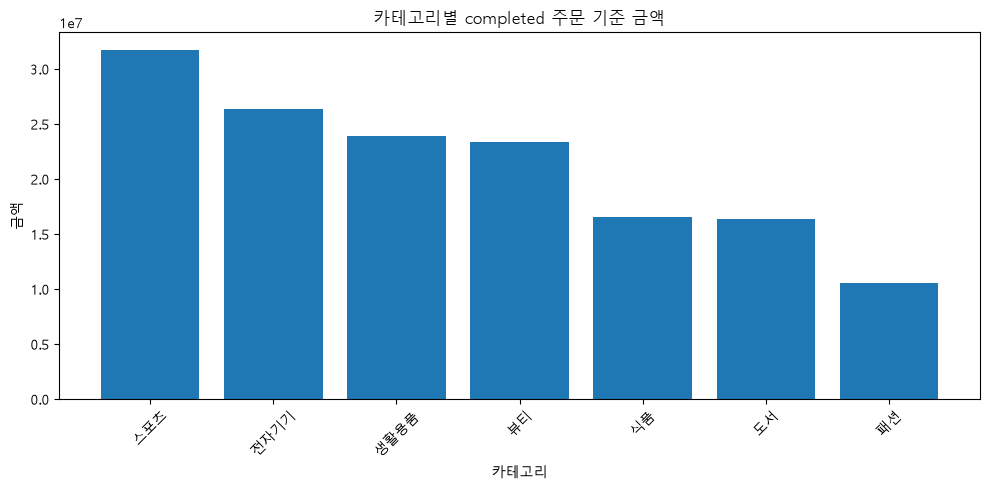

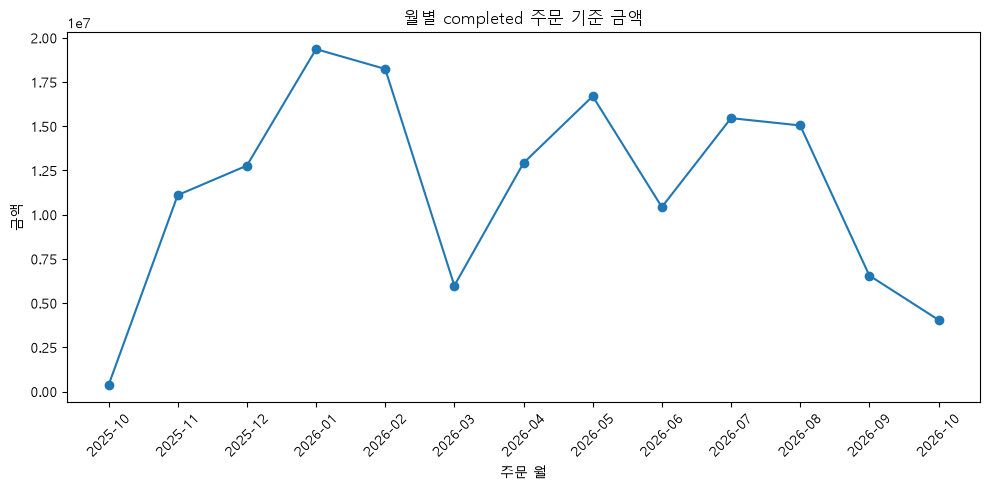

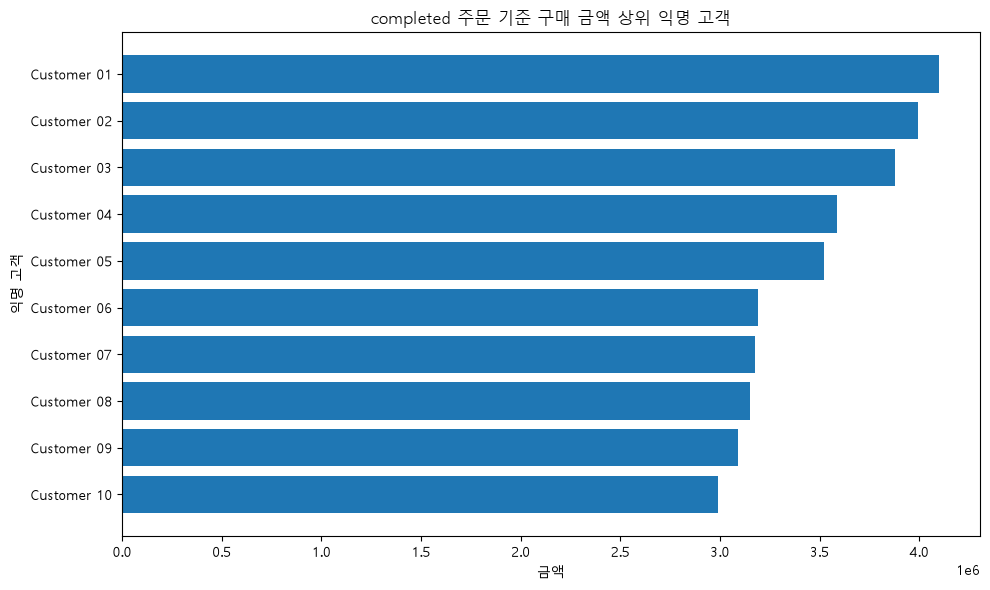

ch08_category_sales.png True 28333
ch08_monthly_sales.png True 79444
ch08_top_customers.png True 47302


In [15]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 6. 대표 시각화

![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)
![대표 그래프 3](images/graph03.png)

### 그래프 선택 이유

1. **카테고리별 completed 주문 기준 금액 막대그래프**  
   카테고리는 순서가 없는 범주형 변수라서 막대 길이로 금액 크기와 순위를 비교하기에 적합하다. 금액 내림차순으로 정렬했고 값 축을 0에서 시작해 범주 간 차이가 과장되지 않게 했다.

2. **월별 completed 주문 기준 금액 선그래프**  
   주문 월은 시간 순서가 있는 변수여서 선그래프로 월별 상승과 하락, 변화 폭을 확인했다. 2025-10부터 2026-10까지 실제 시간 순서로 배치했다. 공통 함수 `create_project_figures()`는 카테고리 막대그래프에만 `set_ylim(bottom=0)`을 적용하고 월별 선그래프에는 Matplotlib 기본 축을 쓴다. 그래서 저장된 선그래프의 금액 축 하단은 0보다 약간 아래에서 시작한다. 축 이름은 단위 없이 `금액`으로 표시되고 `1e7` 지수 표기를 쓰기 때문에 정확한 금액은 월별 집계표와 함께 읽었다.

3. **completed 주문 기준 구매 금액 상위 익명 고객 가로 막대그래프**  
   상위 고객의 순위와 금액 차이를 비교하고 `Customer 01` 형식의 라벨을 읽기 쉽게 하려고 가로 막대를 썼다. 원본 고객 ID나 이름은 그래프에 넣지 않았다.

세 그래프 모두 시각화 단계에서 금액을 다시 계산하지 않았다. 검증이 끝난 `category_sales`, `monthly_sales`, 공개 고객 집계표를 그대로 입력으로 썼다.

### 그래프와 원본 집계값 일치 여부

| 그래프 | 원본 집계값 확인 | 파일 Evidence | 판정 |
| --- | --- | --- | --- |
| 카테고리 막대 | 최고 스포츠 31,743,000원, 최저 패션 10,587,000원 | `ch08_category_sales.png`, 28,333바이트 | PASS |
| 월별 선 | 최고 2026-01 19,360,000원, 최저 2025-10 361,000원 | `ch08_monthly_sales.png`, 79,444바이트 | PASS |
| 익명 고객 가로 막대 | Customer 01 4,100,000원, Customer 02 3,996,000원, Customer 03 3,880,000원 | `ch08_top_customers.png`, 47,302바이트 | PASS |

세 PNG 파일은 모두 존재하고 크기가 0보다 컸다. 카테고리 그래프의 7개 막대, 월별 그래프의 13개 점, 고객 그래프의 상위 10개 막대는 각각 원본 집계표의 행과 같은 순서와 값을 사용했다. 세 집계표의 전체 금액은 모두 completed source 148,990,000원과 일치했다.

### 그래프에서 직접 관찰한 사실

**카테고리 그래프**

스포츠 막대가 31,743,000원으로 가장 길고 패션이 10,587,000원으로 가장 짧다. 두 값의 차이는 21,156,000원이며 스포츠가 패션의 약 3.0배다. 생활용품 23,915,000원과 뷰티 23,383,000원은 막대 길이가 매우 비슷하고 실제 차이도 532,000원에 불과하다. 식품과 도서도 각각 16,573,000원과 16,389,000원으로 184,000원밖에 차이 나지 않아서 순위만 강조하면 차이를 과장할 수 있다.

**월별 그래프**

2025-10의 361,000원에서 2026-01의 19,360,000원까지 높아진 뒤 2026-03에는 5,987,000원으로 크게 내려간다. 2026-05 16,696,000원, 2026-07 15,458,000원, 2026-08 15,046,000원처럼 높은 구간이 다시 나타나지만 지속적인 직선 상승이나 하락은 보이지 않는다. 2026-02에서 2026-03으로 12,252,000원 감소한 구간이 가장 두드러진다. 시작 월과 종료 월은 부분 기간일 가능성이 있어 선의 양 끝을 일반적인 추세로 해석하지 않았다.

**익명 고객 그래프**

상위 세 고객은 3,880,000원 이상이고 1위 Customer 01과 10위 Customer 10의 차이는 1,110,000원이다. 상위 10명 사이의 총금액 차이는 카테고리 최고와 최저의 차이보다 상대적으로 좁다. 그래프의 막대는 총금액만 보여 주므로 Customer 01의 5건과 Customer 06의 2건처럼 구매 빈도가 다른 사실은 표를 함께 봐야 알 수 있다.

### 나의 해석과 판단

질문과 데이터 유형에 맞춰 그래프 형식을 달리한 선택은 적절했다고 판단했다. 범주 비교에는 막대, 시간 변화에는 선, 순위 비교에는 가로 막대가 가장 직접적이었다. 그래프로는 차이를 빠르게 찾을 수 있을 뿐, 정확한 원인이나 업무 결론이 자동으로 나오지는 않는다. 그래서 막대와 선에서 눈에 띄는 지점을 원본 표의 정확한 금액, 수량, 주문 수와 다시 대조했다.

카테고리 그래프에서 스포츠가 높다는 사실은 확인되지만 판매 수량과 단가 중 무엇의 영향인지는 그래프 하나로 알 수 없다. 월별 그래프의 급등락도 주문 수와 평균 주문 금액을 함께 봐야 하며, 고객 그래프의 상위 순위 역시 빈도형과 고액형을 구분해야 한다. 이 때문에 시각적 관찰과 해석을 분리했다.

### 업무·분석적 의미

세 그래프를 함께 보면 범주, 시간, 고객의 세 관점에서 추가 확인할 대상을 빠르게 정할 수 있다. 카테고리 담당자는 스포츠와 패션의 수량/단가 구조를, 운영 담당자는 2026-03과 양 끝 월의 주문 상태/기간 범위를, 고객 분석 담당자는 상위 익명 고객의 빈도와 주문당 금액을 후속 분석할 수 있다. 정확한 수치 표와 함께 제시하면 보고자가 막대 길이나 선 모양만 보고 과도하게 판단하는 위험도 줄일 수 있다.

### 그래프만으로 말할 수 없는 것

- 스포츠 금액이 높은 원인이 선호도, 광고, 프로모션, 재고 또는 수익성 때문인지 알 수 없다.
- 월별 변동이 계절성인지, 행사인지, 데이터 수집 기간 차이인지 그래프만으로 구분할 수 없다.
- 상위 익명 고객의 높은 금액이 충성도, 만족도, 미래 구매 또는 생애가치를 의미하지 않는다.
- completed 주문의 `line_total`은 회계상 순매출이나 이익이 아니다.
- 순위 차이가 통계적으로 안정적인지, 다른 기간에도 유지되는지는 확인하지 않았다.

### 한계와 추가 확인 사항

제출 환경에서는 Notebook에 포함된 그래프 출력과 함께 Markdown 이미지 경로, GitHub 렌더링도 확인해야 한다. 월별 그래프는 완전한 월만 다시 비교하거나 일평균 금액을 계산해 부분 기간 영향을 줄일 필요가 있다. 카테고리에 판매 수량, 평균 단가, 상품 수를 더하고 고객에 최근 구매일과 재구매 간격을 더해야 현재 그래프에서 보인 차이를 더 안전하게 해석할 수 있다.

## 7. 개인정보 검증

- 공개 고객 CSV 컬럼: `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`
- 원본 `customer_id` 포함 여부: 포함하지 않음, 0개
- 이름/이메일/전화번호/주소 포함 여부: 포함하지 않음, 금지 컬럼 0개
- 익명 라벨 방식: completed 구매 금액 내림차순에 따라 `Customer 01`, `Customer 02` 형식으로 새로 부여한 순위 기반 라벨
- PASS/FAIL: 메모리 DataFrame과 저장 후 다시 읽은 CSV 모두 PASS

### 결과 관찰

내부 분석 단계의 고객 집계에는 주문과 고객을 정확히 연결하기 위한 원본 `customer_id`가 있었다. 공개용 결과를 만들 때는 필요한 다섯 컬럼만 명시적으로 선택해 원본 ID, 이름, 이메일, 전화번호, 주소를 제거했다. 메모리 DataFrame에서 확인한 금지 컬럼 목록은 `[]`였고, 실제 저장된 `reports/ch08_customer_sales.csv`를 다시 읽어 검사한 결과도 `[]`였다.

익명 라벨은 현재 completed 구매 금액 순위에 따라 새로 생성했다. 원본 ID의 일부를 가리거나 해시한 값은 쓰지 않았다. `Customer 01`은 이 실행 결과의 금액 1위를 의미할 뿐이고 원본 고객 번호나 개인정보와 직접 연결되지 않는다. 공개 CSV에 도시는 남아 있지만 직접 식별정보 네 종류와 원본 ID는 포함되지 않았다.

### 나의 판단

저장 전과 저장 후를 모두 검사했기 때문에 코드상 DataFrame뿐 아니라 최종 파일에도 같은 정책이 적용됐다고 판단했다. 내부 계산용 키와 외부 공개용 결과를 분리한 방식도 적절하다. 원본 ID는 정확한 병합에 필요해서 내부에서 무조건 제거할 수 없다. 공개 단계에서는 분석 목적에 필요한 집계값과 익명 라벨만 남겨야 최소 정보 원칙에 맞는다.

원본 ID의 앞뒤 문자만 가리는 방식은 다른 자료와 결합했을 때 역추적될 수 있다. 이번 순위 라벨은 그런 직접 연결 가능성을 줄인다. 순위는 고정된 가명 식별자가 아니어서 기간 간 동일 고객 추적에는 쓸 수 없는데 공개용 결과에서는 이 점이 오히려 개인정보 노출을 줄이는 장점이 된다.

### 업무·분석적 의미

내부 분석 테이블과 공개 결과의 스키마를 분리하면 관계 검증과 집계 정확성을 유지하면서 불필요한 개인정보 배포를 줄일 수 있다. 저장 파일을 다시 읽어 자동 검사하면 이후 코드가 변경되어 금지 컬럼이 실수로 추가되는 경우에도 제출 전에 발견할 수 있다. 익명 고객 그래프와 보고서도 같은 공개 스키마를 사용하므로 Notebook뿐 아니라 파생 산출물까지 일관된 정책을 적용할 수 있다.

### 한계와 추가 확인 사항

이번 Privacy Gate는 컬럼 이름과 원본 ID 제거를 중심으로 검사한다. 자유 텍스트 안에 들어간 개인정보나 컬럼 이름이 바뀐 직접 식별정보는 탐지하지 못할 수 있다. `city`는 직접 식별정보가 아니지만 구매 금액, 주문 횟수, 외부 자료와 결합되면 소수 고객을 재식별할 위험이 있다. 실제 공개 대상과 집단 크기에 따라 도시를 더 큰 권역으로 범주화하거나 제거하고, 최소 그룹 크기 기준과 접근 권한도 추가 검토해야 한다.

## 8. 최종 Validation

`reports/ch08_project_validation.csv`의 결과는 다음과 같다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 네 PK의 결측 0건, 중복 0건 |
| fk_integrity | PASS | 세 FK의 미매칭 0건 |
| merge_checks_pass | PASS | 세 병합 모두 예상 `validate` 통과, 행 수 변화 0건, 미매칭 0건 |
| line_total_consistency | PASS | 전체 주문 상세 764행의 계산 불일치 0건 |
| completed_total_consistency | PASS | source/category/month/customer 모두 148,990,000원, 차이 각각 0원 |
| category_sales_ratio_pct_sum | PASS | 카테고리 금액 비중 합계 100.0% |
| completed_rows_with_invalid_order_date | PASS | 날짜 오류 0건, 영향 금액 0원 |
| public_customer_columns_safe | PASS | 메모리 및 저장 CSV의 금지 컬럼 0개 |

### 결과 관찰

8개 검증 항목이 모두 PASS였고 FAIL은 0개였다. 검증 범위는 키와 관계, 병합, 상세 금액 계산, 서로 다른 집계 총합, 비중 합계, 날짜 변환, 공개 고객 컬럼까지 포함한다. 분석 표와 그래프의 생성 여부에 더해 그 결과를 만드는 주요 단계마다 기대 조건을 수치로 대조했다.

`pk_integrity`, `fk_integrity`, `merge_checks_pass`는 관계형 데이터 구조를 확인한다. `line_total_consistency`와 `completed_total_consistency`는 금액 계산과 집계 보존을 확인한다. `category_sales_ratio_pct_sum`과 날짜 검증은 비중과 시간 집계의 누락을 확인하고 `public_customer_columns_safe`는 결과 공개 단계의 개인정보 정책을 확인한다. 서로 다른 위험을 하나의 PASS/FAIL 표로 모은 점이 중요하다.

### FAIL이 있었다면 수정 내용

이번 실행에는 FAIL이 없어 수정 후 재검증한 항목도 0개다. FAIL이 발생했다면 결과값만 강제로 맞추지 않고 원인을 수정한 뒤 전체 파이프라인을 다시 실행한다.

- PK/FK FAIL: 키 중복/결측 또는 부모 없는 참조값의 원본과 처리 규칙 확인
- 병합 FAIL: `validate` 관계와 병합 키, 병합 전후 행 수 확인
- 금액 FAIL: `quantity`, `unit_price`, `line_total`의 타입과 계산식 확인
- 총합 FAIL: completed 필터와 groupby 누락, 날짜 오류, 미매칭 확인
- 개인정보 FAIL: 공개 컬럼 선택 로직을 수정하고 저장 파일을 다시 검사

저장 파일을 직접 다시 읽어 확인한 결과(`pd.read_csv(REPORT_DIR / "ch08_project_validation.csv")`)도 8개 항목 모두 `status == "PASS"`였다. 필수 CSV 15개도 모두 `pd.read_csv()`로 다시 열어 읽기 오류가 없고 행 수가 0보다 큰 것을 확인했다.

### 나의 해석과 판단

현재 정의한 데이터 품질, 계산, 개인정보 기준에서는 제출 가능한 상태라고 판단했다. 모든 검증이 같은 실행에서 만들어지고 CSV로 저장됐기 때문에 사람이 Notebook 화면을 보고 수동으로 PASS를 적은 결과보다 재현성이 높다. 3절의 관계 검증, 5절의 총합 검증, 7절의 개인정보 검증이 최종 표에서 다시 요약되어 Evidence 간 연결도 유지된다.

PASS를 “분석 내용이 전부 옳다”는 의미로 확대하지는 않았다. 예를 들어 카테고리 값이 업무적으로 잘못 분류되어도 총합은 일치할 수 있고, 그래프 제목이 오해를 유발해도 자동 검증은 통과할 수 있다. 자동 Gate가 확인하는 범위와 사람이 검토해야 하는 범위는 구분해야 한다.

### 업무·분석적 의미

원본이나 코드가 바뀌면 자동 Validation으로 이전과 같은 계약이 유지되는지 빠르게 확인한다. 여러 사람이 결과를 검토할 때도 “문제가 없어 보인다”는 말 대신 어떤 조건이 몇 건, 몇 원으로 통과했는지를 공통 근거로 삼는다. 보고서 생성 전에 이 Gate를 실행하면 구조적 오류가 있는 결과가 배포되는 위험을 줄일 수 있다.

### 한계와 추가 확인 사항

현재 검증은 미리 정의한 8개 조건에 한정된다. 질문의 적절성, 시각화의 전달력, 원인 해석, 통계적 불확실성, 도메인 타당성은 자동화되지 않았다. 원본 파일의 스키마가 예상과 다르게 바뀌거나 새로운 개인정보 컬럼이 추가되는 상황을 더 강하게 방어하려면 허용 컬럼 목록, 타입/범위 검사, 스키마 버전, CI 실행을 추가할 필요가 있다.

## 실행 단계 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [16]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\dev\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items 

## 실행 단계 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [17]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/dev/llm-data-analysis-course/reports/ch08_midterm_report.md')

In [18]:
reproduced_analysis = project_result["analysis_tables"]
reproduced_totals = reproduced_analysis["total_consistency_check"]

notebook_totals = {
    "completed_source": float(total_consistency.loc[
        total_consistency["source"].eq("completed_source"), "amount"
    ].iloc[0]),
    "category": float(category_sales["total_sales"].sum()),
    "monthly": float(monthly_sales["total_sales"].sum()),
    "customer": float(customer_sales_internal["total_sales"].sum()),
}
script_totals = dict(zip(
    reproduced_totals["source"],
    reproduced_totals["amount"],
))

reproduction_comparison = pd.DataFrame({
    "source": list(notebook_totals),
    "notebook_amount": list(notebook_totals.values()),
    "script_amount": [float(script_totals[key]) for key in notebook_totals],
})
reproduction_comparison["difference"] = (
    reproduction_comparison["script_amount"]
    - reproduction_comparison["notebook_amount"]
)
reproduction_comparison["matches"] = np.isclose(
    reproduction_comparison["notebook_amount"],
    reproduction_comparison["script_amount"],
)

display(reproduction_comparison)
assert reproduction_comparison["matches"].all()
print("Notebook / 전체 재실행 핵심 금액 비교: PASS")


,source,notebook_amount,script_amount,difference,matches
0,completed_source,148990000.0,148990000.0,0.0,True
1,category,148990000.0,148990000.0,0.0,True
2,monthly,148990000.0,148990000.0,0.0,True
3,customer,148990000.0,148990000.0,0.0,True


Notebook / 전체 재실행 핵심 금액 비교: PASS


## 실행 단계 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [19]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


In [20]:
# 저장된 Validation CSV와 필수 CSV 15개를 실제로 다시 읽어 확인
saved_validation = pd.read_csv(REPORT_DIR / "ch08_project_validation.csv")
display(saved_validation)
assert saved_validation["status"].eq("PASS").all(), "저장된 Validation에 FAIL이 있습니다."
print("저장된 Validation CSV:", len(saved_validation), "개 항목 모두 PASS")

csv_read_checks = []
for path in [p for p in expected_outputs if p.suffix == ".csv"]:
    df = pd.read_csv(path)
    csv_read_checks.append(dict(file=path.name, rows=len(df), columns=len(df.columns)))

csv_read_checks = pd.DataFrame(csv_read_checks)
display(csv_read_checks)
assert len(csv_read_checks) == 15
assert csv_read_checks["rows"].gt(0).all()
print("필수 CSV 15개 pd.read_csv() 읽기: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


저장된 Validation CSV: 8 개 항목 모두 PASS


,file,rows,columns
0,ch08_dataset_summary.csv,4,5
1,ch08_preprocessing_comparison.csv,4,5
2,ch08_key_duplicate_checks.csv,4,6
3,ch08_relationship_checks.csv,3,3
4,ch08_merge_checks.csv,3,7
5,ch08_line_total_check.csv,1,5
6,ch08_date_checks.csv,1,4
7,ch08_amount_scope_summary.csv,3,3
8,ch08_total_consistency_check.csv,4,5
9,ch08_project_validation.csv,8,4


필수 CSV 15개 pd.read_csv() 읽기: PASS


## 실행 단계 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


### 9 LLM 답변 (원문, Gemini flash-lite 이용)
제시해주신 온라인 쇼핑몰 중간 프로젝트의 검증 결과와 계산 기준을 바탕으로, 요청하신 5가지 항목에 대해 검토한 의견을 정리해 드립니다.

---

### 1. 아직 확인하지 않은 분석 위험 (Unchecked Analysis Risks)

* **환불 및 반품(Refund/Return) 반영 여부:** `order_status == completed` 조건만으로 매출을 산정할 경우, 완료 후 발생한 환불이나 취소 건이 반영되지 않아 매출액이 과대평가(Overestimation)될 위험이 있습니다.
* **단가 및 수량의 이상치(Outlier) 잔존 여부:** PK/FK와 총합 검증은 통과했으나, 개별 `quantity`나 `unit_price`에 비정상적인 값(예: 음수, 0, 터무니없이 큰 오입력 값)이 포함되어 있을 가능성이 남아 있습니다.
* **고객 ID 비명명화(Anonymization)로 인한 왜곡:** 공개 고객 CSV에 원본 `customer_id`가 없어 대체 ID나 매핑 키를 사용했을 경우, 고객 단위 집계(재구매율, 고객 생애 가치 등)에서 식별 오류가 발생했을 위험이 있습니다.

### 2. 과도한 해석이 될 수 있는 표현 (Over-interpretations)

* **매출과 이익의 혼동:** `line_total`은 총 주문 금액(Revenue)이므로, 이를 '순이익(Net Profit)'이나 '수익성'으로 해석하는 표현은 금물입니다. (원가(COGS)나 운영 비용 데이터가 없는 한 이익 언급 불가)
* **인과관계 단정:** 특정 월이나 카테고리의 매출 증감을 마케팅 효과, 트렌드 변화, 고객 만족도 등 **데이터에 존재하지 않는 외생 변수로 원인을 단정**하는 표현.
* **고객 행동 성향 단정:** 구매 주기가 짧거나 길다는 이유로 고객의 충성도나 불만을 추정하는 표현.

### 3. 보고서에 반드시 적어야 할 계산 기준 (Mandatory Calculation Standards)

보고서의 신뢰성을 위해 본문에 명시해야 할 핵심 기준은 다음과 같습니다.

* **매출 산정 공식:** $\text{line\_total} = \text{quantity} \times \text{unit\_price}$ 및 주문 단위 합산 방식
* **데이터 필터링 기준:** 금액성 분석(매출, 객단가 등) 시 `order_status == completed` 상태인 데이터만 추출하여 산출함
* **데이터 범위 및 제약:** 공개 고객 CSV의 특성으로 인해 원본 `customer_id`가 제외된 상태에서 분석이 수행되었음을 명시

### 4. 추가로 필요한 검증 (Additional Required Validations)

* **결측 및 이상치 검증:** `quantity` 및 `unit_price`의 최솟값, 최댓값, 분포 확인 (음수 및 0원 상품 존재 여부)
* **주문 상태별 비중 분석:** `completed` 외의 상태(cancelled, refunded 등)의 비율과 규모 확인
* **고객 식별 키 무결성 검증:** 고객 ID 비명명화 과정에서 데이터 유실이나 중복 매핑이 발생하지 않았는지 교차 검증

### 5. 데이터에 없는 원인은 추정하지 않기 (Strict Adherence to Data)

* 데이터에 나타난 수치적 증감(예: "특정 카테고리의 매출이 20% 증가함")은 사실(Fact)로 서술하되, 그 이유(예: "해당 제품의 품질이 좋아서", "타사 경쟁사 이슈로 반사이익을 얻어서")는 데이터에 명시되어 있지 않다면 일체 배제해야 합니다.
* 현상과 지표의 변화 자체에 집중하고, 주관적인 비즈니스 인사이트나 원인 추정은 "추가 데이터 확보를 통한 원인 분석이 필요함"으로 한정해야 합니다.

## 9. LLM 활용 기록

- 사용 여부: 사용함
- 사용 목적: completed 주문 기준 분석에서 아직 확인하지 않은 위험, 과도한 해석, 보고서에 반드시 적어야 할 계산 기준과 추가 검증 항목을 검토하는 데 사용했다. 계산 결과를 새로 만드는 데는 쓰지 않았다.
- Safe Context: 비식별 검증 요약만 제공했다. 계산 기준은 `line_total = quantity × unit_price`와 금액성 분석에 `order_status == "completed"`만 사용한다는 것이고 검증 요약은 PK 결측/중복 0건, FK 미매칭 0건, 병합 검사 PASS, category/month/customer 총합 일치, completed 날짜 오류 0건, 공개 고객 CSV에 원본 `customer_id`가 없다는 내용이다.
- 제공하지 않은 정보: 고객 원본 행, 이름, 이메일, 전화번호, 주소, 원본 `customer_id`, 개별 고객의 주문 내역
- Prompt 요약: ① 아직 확인하지 않은 분석 위험, ② 과도한 해석이 될 수 있는 표현, ③ 보고서에 반드시 적을 계산 기준, ④ 추가로 필요한 검증, ⑤ 데이터에 없는 원인을 추정하지 않는 방법을 검토하도록 요청했다.
- 제안 요약: completed 상태만 사용할 때 완료 후 환불/취소가 별도로 존재할 가능성, `quantity`/`unit_price` 이상치 가능성, 고객 익명화 과정의 집계 오류 가능성을 위험으로 제시했다. 주문 기준 금액을 이익으로 해석하거나 월/카테고리 차이를 마케팅, 트렌드, 만족도의 인과관계로 단정하지 말라는 제안도 있었다. 계산식과 completed 필터를 보고서에 명시하고 수량/단가 분포, 주문 상태별 비중, 익명화 전후 고객 집계를 추가 검증하라고도 했다.
- 반영/수정/보류: 계산식/completed 범위 명시, 이익/인과/고객 성향 단정 금지, 주문 상태별 비중 확인은 반영했다. 현재 데이터가 할인, 배송비, 세금, 부분 환불을 반영하지 않아 LLM이 사용한 “매출” 표현은 “completed 주문 기준 금액”으로 수정했다. 공개 CSV에서 ID가 없기 때문에 ID 없이 고객 집계를 수행했다는 취지의 설명은 사실과 달라 수정했다. 고객 집계는 내부 `customer_id`로 먼저 수행하고 관계를 검증한 뒤 공개 단계에서 원본 ID를 제거했다. 완료 후 상태 변경 이력과 수량/단가 이상치의 업무 기준은 추가 확인 항목으로 보류했다. 현재 최종 Gate만으로는 충분히 확인되지 않기 때문이다.
- 사람이 검증한 근거: 전체 주문 300건 중 completed 184건(61.33%), cancelled 64건(21.33%), refunded 52건(17.33%)을 실제 상태 집계표로 확인했다. 네 PK 결측/중복과 세 FK 미매칭은 모두 0건, 병합 행 수 변화와 미매칭도 0건이었다. `line_total` 764행의 계산 불일치는 0건이고 completed source/category/month/customer는 모두 148,990,000원으로 차이가 각각 0원이었다. 고객 내부 집계와 고객 마스터의 `one_to_one` 병합은 100→100행, 미매칭 0건이었다. 공개 CSV를 다시 읽은 결과 금지 컬럼은 `[]`였다.

### 실제 LLM 응답에서 확인한 제안

| LLM 제안 | 처리 | 사람이 확인하거나 수정한 내용 |
| --- | --- | --- |
| completed만 집계하면 완료 후 환불이 반영되지 않을 수 있음 | 보류/한계 반영 | 현재 데이터에는 상태 변경 이력이 없어 “완료 후 환불” 여부를 확인할 수 없다. 현재 스냅샷의 cancelled/refunded 116건은 completed 금액에서 제외했다. |
| `quantity`, `unit_price`의 0, 음수, 극단값 확인 | 추가 확인으로 보류 | PK/FK와 총합 PASS만으로 값 범위의 업무 타당성은 보장되지 않는다. 도메인 허용 범위를 정한 뒤 별도 검사해야 한다. |
| 익명화로 고객 단위 집계가 왜곡될 수 있음 | 설명 수정 후 검증 | 내부 원본 ID로 집계를 완료한 뒤 금액 순위 라벨을 부여했다. 고객 병합 100→100행, 미매칭 0건과 공개 CSV 금지 컬럼 0개를 확인했다. |
| 주문 기준 금액을 순이익/수익성으로 해석하지 않기 | 반영 | 답안 전체에서 회계상 순매출/이익으로 부르지 않고 `quantity × unit_price`의 completed 주문 기준 금액으로 한정했다. |
| 월/카테고리 변화의 원인을 데이터 밖 변수로 단정하지 않기 | 반영 | 프로모션, 선호도, 계절성과 만족도는 원인이 아니라 추가 데이터가 필요한 가설로만 남겼다. |
| 계산식과 completed 필터를 보고서에 명시 | 반영 | 1절, 4~6절, 11절과 Markdown 보고서에 동일한 계산 계약을 명시했다. |
| 주문 상태별 비중 확인 | 반영/검증 | completed 61.33%, cancelled 21.33%, refunded 17.33%로 확인했다. |

### 결과 관찰

실제 LLM 응답은 해석 위험을 넓게 찾는 데 도움이 됐지만, 일부 문장은 현재 처리 순서를 정확히 반영하지 못했다. “공개 고객 CSV에 원본 ID가 없으므로 원본 ID가 제외된 상태에서 분석했다”는 취지가 대표적인데, 이 설명은 맞지 않는다. 내부 원본 ID로 관계 검증과 고객 집계를 수행한 뒤 공개 결과를 만들 때 원본 ID를 제거하고 순위 기반 라벨을 붙였다. 이것이 정확한 절차다.

LLM이 지적한 완료 후 환불 위험은 일반적으로 타당하지만 현재 데이터는 주문 상태의 변경 이력을 제공하지 않는다. 그래서 완료 후 환불이 실제로 있었다거나 금액이 과대평가됐다고 단정하지 않았다. 현재 스냅샷에서 cancelled/refunded 주문을 제외했다는 사실과 상태 이력 자료가 필요하다는 한계를 구분해 적었다.

### 나의 해석과 판단

LLM 제안은 검토 체크리스트로 사용했고 최종 판정을 맡기지 않았다. 실행 결과로 확인 가능한 제안은 반영하고, 표현이 데이터의 의미보다 넓으면 수정했으며, 현재 자료로 확인할 수 없는 제안은 보류했다. 이 구분이 없으면 일반적으로 그럴듯한 위험을 이번 데이터에서 실제 발생한 문제처럼 잘못 기록할 수 있다.

주문 기준 금액과 이익을 구분하고 데이터에 없는 원인을 배제하라는 지적이 가장 유용했다. 반대로 익명화 관련 설명은 실제 파이프라인 순서를 사람이 확인해 바로잡아야 했다. LLM은 누락 후보를 제시하는 데 활용할 수 있지만 계산값, 처리 순서, PASS 여부는 코드 출력과 저장 파일을 기준으로 사람이 결정해야 한다.

### 업무·분석적 의미

Prompt, 실제 응답, 반영/수정/보류와 검증 근거를 함께 남기면 LLM을 사용했더라도 어떤 판단이 실행 Evidence에 근거했는지 추적할 수 있다. Safe Context만 제공하면 개인정보 노출이 줄고 제안을 그대로 복사하지 않고 검증하면 잘못된 인과 해석과 용어 확장을 막는다.

### 한계와 추가 확인 사항

현재 Validation에는 `quantity`와 `unit_price`의 도메인 허용 범위, 주문 상태 변경 이력, 익명화 결과의 기간 간 안정성이 포함되지 않았다. 상태 변경 이력이 확보되면 completed 이후 환불/취소 여부와 영향 금액도 다시 검증해야 한다. 제출 전에는 9절 기록이 실제 사용 과정과 일치하는지 확인하고 향후에는 수량/단가의 최소, 최대, 분포와 0/음수 값을 별도 Gate로 추가하는 것이 좋다.

## 10. 프로젝트 재현 확인

- `python scripts/run_midterm_project.py` 실행 여부: 실행함. 프로젝트 루트에서 명령줄로 실행해 원본부터 보고서까지 오류 없이 완료되었고 최종 Validation 8개 항목이 모두 PASS로 출력됨
- 재실행 결과: 원본 로딩, 전처리, PK/FK, 병합, 금액 검증, 집계, 공개 결과, 그래프, CSV와 Markdown 보고서 생성까지 오류 없이 완료
- Notebook과 핵심 수치 일치 여부: completed source, category, monthly, customer 금액이 모두 148,990,000원으로 일치하고 차이는 각각 0원
- 생성된 핵심 Evidence 파일 확인 여부: CSV 15개, PNG 3개, Markdown 1개로 총 19개 파일이 모두 존재하고 크기가 0보다 큼
- 최종 Validation: 8개 항목 모두 PASS, FAIL 0개

![재실행 결과](images/step06_reproduce.png)

### Notebook과 전체 재실행 핵심 수치 비교

| 기준 | Notebook 금액 | 전체 재실행 금액 | 차이 | 일치 |
| --- | ---: | ---: | ---: | --- |
| completed source | 148,990,000원 | 148,990,000원 | 0원 | True |
| category | 148,990,000원 | 148,990,000원 | 0원 | True |
| monthly | 148,990,000원 | 148,990,000원 | 0원 | True |
| customer | 148,990,000원 | 148,990,000원 | 0원 | True |

### 결과 관찰

단계별 Notebook의 네 핵심 금액은 전체 파이프라인을 처음부터 다시 실행해 만든 네 금액과 모두 일치했다. source와 세 분석 차원의 값이 각각 0원 차이라서 어느 한 집계만 우연히 같은 경우도 아니다. 재실행 후 최종 Validation도 PK/FK, 병합, `line_total`, total consistency, 비중 합계, 날짜, 개인정보 항목 모두 PASS였다.

필수 산출물 검증에서는 검증 CSV와 결과 CSV가 확인됐다. 검증 CSV는 dataset summary, preprocessing comparison, PK, FK, merge, `line_total`, date, total consistency, project validation 등이고 결과 CSV는 category, monthly, public customer, order status, interpretation notes 등이다. 카테고리, 월, 익명 고객 PNG 3개와 `ch08_midterm_report.md`도 존재했고 빈 파일은 0개였다. 재실행은 화면에 같은 숫자를 출력하는 데 그치지 않고 제출에 필요한 파일까지 다시 만들었다.

### 나의 해석과 판단

단계별 셀의 변수 상태와 무관하게 원본부터 전체 결과가 다시 생성됐다. 현재 프로젝트가 우연한 셀 실행 순서나 이전 메모리의 남은 값에 의존한다는 징후는 없다. Notebook을 위에서 아래로 실행한 결과와 공통 파이프라인 함수의 결과도 같아서 분석 로직이 두 경로에서 일관되게 사용됐다는 근거가 된다.

Notebook에서는 셀을 선택적으로 실행하다 보면 이전 값이 남아 오류가 가려질 수 있다. 전체 재실행은 그런 숨은 상태를 제거하고도 같은 결과가 나오는지를 확인한다. 네 총합 차이 0원과 산출물 19개 `OK`를 함께 확인했기 때문에 숫자 재현성과 파일 재현성을 모두 검증했다고 판단했다.

### 재실행 가능한 프로젝트가 중요한 이유

재실행 가능해야 다른 사람이 같은 원본과 환경에서 결과를 검증할 수 있다. 원본이나 코드가 바뀌었을 때 모든 표, 그래프, 보고서를 같은 기준으로 다시 만들 수도 있다. 수작업으로 복사한 숫자와 그림은 수정 시 서로 다른 버전이 남기 쉽지만 하나의 파이프라인은 계산 기준과 Evidence를 함께 갱신한다.

업무에서는 결과 자체보다 결과가 어떻게 만들어졌는지 설명할 수 있어야 한다. PK/FK와 병합 관계, 금액 계산식, 필터 범위, 총합 검증이 코드와 파일로 남아 있으면 리뷰와 인수인계가 쉬워지고 오류가 발생했을 때 어느 단계에서 계약이 깨졌는지 추적할 수 있다.

### 업무·분석적 의미

현재 구조에서는 원본 데이터가 갱신되더라도 동일한 함수와 Validation을 실행해 새 결과를 만들고 이전 결과와 비교할 수 있다. 보고서와 공개 고객 파일도 함께 재생성되므로 분석 결과만 바뀌고 Evidence가 오래된 상태로 남을 위험이 작아진다. 자동 산출물 검사는 배포 전 체크리스트 역할도 한다.

### 한계와 추가 확인 사항

이번 재현성은 현재 Windows 프로젝트 환경, 현재 Python/패키지 상태, 현재 원본 파일에서 확인한 것이다. 다른 운영체제나 패키지 버전에서 같은 결과가 나오는지는 검증하지 않았다. 이를 강화하려면 의존성 버전을 고정하고 깨끗한 환경 또는 CI에서 명령줄 스크립트를 실행해야 한다. Notebook 내부 출력이 정상이어도 GitHub에서는 상대 이미지 경로가 깨질 수 있으므로 제출 전 실제 저장소에서 렌더링과 파일 경로를 별도로 확인해야 한다.

## 실행 단계 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [21]:
# 실습과제 통합 실행·검증
exercise_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)
exercise_tables = exercise_result["analysis_tables"]

# 1. 핵심 EDA 3개 실제 결과 요약
exercise_eda_summary = pd.DataFrame([
    {
        "analysis": "category",
        "top_item": category_sales.iloc[0]["category"],
        "top_amount": float(category_sales.iloc[0]["total_sales"]),
        "supporting_value": float(category_sales.iloc[0]["sales_ratio"]),
    },
    {
        "analysis": "monthly",
        "top_item": monthly_sales.loc[monthly_sales["total_sales"].idxmax(), "order_month"],
        "top_amount": float(monthly_sales["total_sales"].max()),
        "supporting_value": int(monthly_sales.loc[monthly_sales["total_sales"].idxmax(), "order_count"]),
    },
    {
        "analysis": "customer",
        "top_item": customer_sales_public.iloc[0]["customer_label"],
        "top_amount": float(customer_sales_public.iloc[0]["total_sales"]),
        "supporting_value": int(customer_sales_public.iloc[0]["order_count"]),
    },
])
display(exercise_eda_summary)

# 2. 대표 그래프 3개 파일 Evidence
exercise_figure_evidence = pd.DataFrame([
    {
        "figure": path.name,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else 0,
    }
    for path in exercise_result["saved_figures"]
])
display(exercise_figure_evidence)

# 3. Total consistency와 최종 Validation
exercise_total_consistency = exercise_tables["total_consistency_check"].copy()
exercise_validation = exercise_result["project_validation"].copy()
display(exercise_total_consistency)
display(exercise_validation)

# 4. 저장된 공개 고객 CSV 개인정보 재검사
exercise_saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")
exercise_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(exercise_saved_customer.columns)
)
print("저장 공개 고객 CSV 컬럼:", exercise_saved_customer.columns.tolist())
print("저장 공개 고객 CSV 금지 컬럼:", exercise_forbidden)

# 5~6. Notebook 단계별 결과와 전체 재실행 결과 비교
exercise_notebook_totals = dict(zip(
    total_consistency["source"],
    total_consistency["amount"],
))
exercise_rerun_totals = dict(zip(
    exercise_total_consistency["source"],
    exercise_total_consistency["amount"],
))
exercise_reproduction = pd.DataFrame({
    "source": list(exercise_notebook_totals),
    "notebook_amount": [float(exercise_notebook_totals[key]) for key in exercise_notebook_totals],
    "rerun_amount": [float(exercise_rerun_totals[key]) for key in exercise_notebook_totals],
})
exercise_reproduction["difference"] = (
    exercise_reproduction["rerun_amount"]
    - exercise_reproduction["notebook_amount"]
)
exercise_reproduction["matches"] = np.isclose(
    exercise_reproduction["notebook_amount"],
    exercise_reproduction["rerun_amount"],
)
display(exercise_reproduction)

exercise_checks = pd.DataFrame([
    {"check": "three_eda_results", "status": "PASS" if len(exercise_eda_summary) == 3 else "FAIL"},
    {"check": "representative_figures", "status": "PASS" if len(exercise_figure_evidence) in range(2, 5) and exercise_figure_evidence["exists"].all() and exercise_figure_evidence["size_bytes"].gt(0).all() else "FAIL"},
    {"check": "total_consistency", "status": "PASS" if exercise_total_consistency["matches_completed"].all() else "FAIL"},
    {"check": "project_validation", "status": "PASS" if exercise_validation["status"].eq("PASS").all() else "FAIL"},
    {"check": "saved_customer_privacy", "status": "PASS" if not exercise_forbidden else "FAIL"},
    {"check": "notebook_vs_rerun", "status": "PASS" if exercise_reproduction["matches"].all() else "FAIL"},
    {"check": "required_outputs", "status": "PASS" if all(path.exists() and path.stat().st_size > 0 for path in [*exercise_result["saved_tables"], *exercise_result["saved_figures"], exercise_result["report_path"]]) else "FAIL"},
])
display(exercise_checks)
assert exercise_checks["status"].eq("PASS").all()
print("실습과제 통합 검증: PASS")


,analysis,top_item,top_amount,supporting_value
0,category,스포츠,31743000.0,21.31
1,monthly,2026-01,19360000.0,19.00
2,customer,Customer 01,4100000.0,5.00


,figure,exists,size_bytes
0,ch08_category_sales.png,True,28333
1,ch08_monthly_sales.png,True,79444
2,ch08_top_customers.png,True,47302


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


저장 공개 고객 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
저장 공개 고객 CSV 금지 컬럼: []


,source,notebook_amount,rerun_amount,difference,matches
0,completed_source,148990000.0,148990000.0,0.0,True
1,category,148990000.0,148990000.0,0.0,True
2,monthly,148990000.0,148990000.0,0.0,True
3,customer,148990000.0,148990000.0,0.0,True


,check,status
0,three_eda_results,PASS
1,representative_figures,PASS
2,total_consistency,PASS
3,project_validation,PASS
4,saved_customer_privacy,PASS
5,notebook_vs_rerun,PASS
6,required_outputs,PASS


실습과제 통합 검증: PASS


### 실습과제 수행 결과

#### 1. 핵심 EDA 결과 3개

1) 카테고리별 completed 주문 기준 금액

스포츠가 31,743,000원과 21.31%로 가장 높았다. 범주 간 금액 기여 차이를 가장 직접적으로 보여 주므로 선택했다. 스포츠의 수량도 295개로 가장 많다. 그러나 높은 금액이 수량과 단가 중 어느 요인에서 주로 발생했는지, 또는 광고나 선호도 때문인지는 현재 결과만으로 확정할 수 없다.

2) 월별 completed 주문 기준 금액과 주문 수

2026-01이 19,360,000원과 19건으로 금액 최고 월이었다. 월별 금액 변화와 주문 수/평균 주문 금액의 관계를 함께 볼 수 있어 선택했다. 시작 월과 종료 월은 부분 기간일 가능성이 있고 프로모션/계절 자료가 없으므로 변동 원인은 단정하지 않는다.

3) 익명 고객별 completed 구매 금액

Customer 01이 4,100,000원과 5건으로 총금액 1위였다. 상위 고객도 구매 빈도와 평균 주문 금액의 조합이 다르다는 점을 확인하려고 선택했다. 충성도, 미래 가치, 구매 동기는 익명 집계만으로 판단할 수 없다.

세 결과는 모두 같은 completed source에서 출발했다. 관찰된 순위와 패턴은 후속 분석 대상을 고르는 근거로만 사용했다.

#### 2. 대표 그래프 선택과 원본 집계값 대조

| 그래프 | 선택 이유 | 집계표 대조 | 파일 Evidence |
| --- | --- | --- | --- |
| 카테고리 막대그래프 | 범주별 금액 크기와 순위 비교 | 최고 스포츠 31,743,000원으로 집계표와 일치 | `ch08_category_sales.png`, 28,333바이트 |
| 월별 선그래프 | 시간 순서에 따른 상승/하락 확인 | 최고 2026-01, 19,360,000원으로 집계표와 일치 | `ch08_monthly_sales.png`, 79,444바이트 |
| 상위 익명 고객 가로 막대그래프 | 상위 10명의 순위와 금액 비교 | Customer 01, 4,100,000원으로 공개 집계표와 일치 | `ch08_top_customers.png`, 47,302바이트 |

세 파일은 모두 존재하고 크기가 0보다 컸다. 그래프는 검증된 집계표를 입력으로 사용했으며 별도 계산 범위를 만들지 않았다. 시각적 차이만으로 원인이 증명되지는 않으므로 광고 효과, 계절성, 고객 선호 또는 수익성으로 확대 해석하지 않았다.

#### 3. Total consistency와 최종 Validation

- completed source total: 148,990,000원
- category total: 148,990,000원, 차이 0원
- monthly total: 148,990,000원, 차이 0원
- customer total: 148,990,000원, 차이 0원
- 네 결과 모두 `matches_completed=True`, PASS

최종 Validation의 `pk_integrity`, `fk_integrity`, `merge_checks_pass`, `line_total_consistency`, `completed_total_consistency`, `category_sales_ratio_pct_sum`, `completed_rows_with_invalid_order_date`, `public_customer_columns_safe`가 모두 PASS였다. 비중 합계는 100.0%, 날짜 오류는 0건, `line_total` 불일치는 0건이었다.

#### 4. 공개 고객 CSV 개인정보 재검사

저장된 `ch08_customer_sales.csv`의 컬럼은 `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`였다. `customer_id`, 이름, 이메일, 전화번호, 주소에 해당하는 금지 컬럼은 0개(`[]`)였고 저장 후 Privacy Gate를 통과했다. 도시처럼 간접적인 정보도 외부 데이터와 결합하면 재식별 위험을 높일 수 있어서 실제 공개 범위에 따라 추가 일반화를 검토해야 한다.

#### 5. LLM 활용과 검증

LLM은 누락 점검과 과도한 해석 검토에 사용했고 실행 결과를 대신 만들게 하지 않았다. Safe Context로 계산 기준(`line_total = quantity × unit_price`, completed 범위)과 PK/FK, 병합, 총합, 날짜, 공개 고객 CSV 검증 요약만 제공했다. 집계표나 고객별 결과, 원본 고객 행과 직접 식별정보는 제공하지 않았다. 제안은 실제 코드 출력과 assert 결과에 대조했고 데이터에 없는 원인 설명은 반영하지 않았다.

#### 6. 전체 프로젝트 재실행과 Notebook 비교

`run_midterm_project()`로 원본부터 보고서까지 다시 실행했다. completed source, category, monthly, customer의 Notebook 금액과 재실행 금액은 모두 148,990,000원이었고 네 차이는 각각 0원이었다. CSV 15개, PNG 3개, Markdown 보고서 1개 등 필수 산출물 19개가 모두 생성되어 존재/비어 있지 않음 검사를 통과했다.

#### 종합 판단

실습과제 통합 검증의 `three_eda_results`, `representative_figures`, `total_consistency`, `project_validation`, `saved_customer_privacy`, `notebook_vs_rerun`, `required_outputs`가 모두 PASS였다. 따라서 현재 원본과 실행 환경에서는 질문, 계산 범위, 집계, 그래프, 공개 결과와 보고서가 같은 기준으로 재현되는 완료 상태다.

이 금액은 `quantity × unit_price`의 completed 합계이며 회계상 순매출이나 이익이 아니다. 장기 계절성, 프로모션 효과, 고객 선호와 미래 가치를 판단하려면 더 긴 기간과 원가, 할인, 마케팅, 고객 행동 자료가 필요하다.


## 11. 최종 프로젝트 요약

### 핵심 인사이트 3개

1. 카테고리별 주문 기준 금액은 규모 차이가 있지만 순위만으로 원인을 설명할 수 없다.
   completed 주문 기준 스포츠가 31,743,000원과 21.31%로 가장 높았고 패션은 10,587,000원과 7.11%로 가장 낮았다. 차이는 21,156,000원과 14.20%p이며 스포츠 금액은 패션의 약 3.0배다. 스포츠의 판매 수량도 295개로 가장 높았다. 그런데 전자기기는 생활용품보다 수량이 13개 적으면서 금액은 2,485,000원 높았다. 금액 순위는 수량과 단가를 함께 분해해서 봐야 하며 현재 결과만으로 선호도나 수익성이 높다고 판단할 수 없다.

2. 월별 총금액은 주문 수와 평균 주문 금액의 조합에 따라 달라졌다.
   금액 최고 월은 2026-01의 19,360,000원으로 주문 19건과 평균 주문 금액 1,018,947원이었다. 주문 수 최고 월은 2026-05의 24건이지만 총금액은 16,696,000원, 평균 주문 금액은 695,667원이었다. 거래 횟수가 가장 많은 달과 총금액이 가장 높은 달이 같지 않았던 셈이다. 2026-02에서 2026-03으로 금액이 12,252,000원 감소할 때 주문 수도 21건에서 8건으로 줄었다. 이것만으로 수요 감소나 행사 종료를 원인으로 단정할 수 없고 양 끝 월은 부분 기간일 가능성도 있다.

3. 상위 익명 고객도 구매 빈도형과 고액 주문형으로 구분할 필요가 있다. 
   Customer 01은 5건과 4,100,000원으로 총금액 1위였고 평균 주문 금액은 820,000원이었다. Customer 06과 07은 각각 2건이지만 평균 주문 금액이 1,595,500원과 1,589,000원으로 높았다. Customer 04는 Customer 01과 같은 5건이지만 평균 주문 금액이 718,000원이라 총금액이 510,000원 낮았다. 총금액 하나로 상위 고객을 같은 유형으로 취급하지 말고 주문 빈도, 평균 주문 금액, 최근 구매일을 함께 봐야 한다.

### 결과를 종합한 관찰과 판단

카테고리, 월, 고객이라는 세 관점의 결과는 서로 다른 패턴을 보여 주지만 출발점은 모두 동일한 completed source 148,990,000원이다. category, monthly, customer 총합은 각각 148,990,000원이고 source와의 차이는 모두 0원이었다. 네 PK의 결측/중복, 세 FK의 미매칭, 세 병합의 행 수 변화, `line_total` 불일치, completed 날짜 오류, 공개 고객 금지 컬럼도 모두 0건이었다.

이 결과로 가장 강하게 말할 수 있는 사실은 질문, 계산 범위, 집계표, 그래프, 보고서가 같은 completed 계약을 유지했다는 점이다. 특정 카테고리나 고객이 “좋다”는 평가는 여기서 나오지 않는다. 카테고리 순위, 월별 등락, 고객 순위는 후속 분석 대상을 정하는 근거일 뿐 원인이나 인과관계의 증거는 아니다. 자동 Validation 8개 PASS도 데이터 처리 계약을 충족했다는 결과이며 해석이 자동으로 옳아지지는 않는다.

### 가장 중요한 업무·분석적 의미

의사결정에 사용되는 여러 표와 그래프가 같은 모집단과 계산식을 사용해야 비교가 가능하다. 이번 프로젝트에서는 금액을 completed 주문 상세의 `quantity × unit_price`로 고정하고 주문 수는 고유 `order_id`로 계산했다. 이 기준을 카테고리, 월, 고객 결과와 보고서 전체에 적용했으며 source total 대조로 일관성을 확인했다.

업무적으로는 결과 순위보다 검증 가능한 분석 흐름이 더 중요하다. 원본을 보존한 전처리, PK/FK와 병합 Gate, 금액/날짜/총합 검증, 개인정보 분리, 전체 재실행을 연결하면 원본이나 코드가 변경됐을 때 오류를 빠르게 찾을 수 있다. 공개 결과에서는 원본 고객 ID와 직접 식별정보를 제거해 분석 활용과 개인정보 보호를 동시에 고려했다.

### 현재 분석의 한계

- 금액은 `quantity × unit_price`이며 할인, 쿠폰, 배송비, 세금, 수수료, 부분 환불과 원가를 반영한 순매출이나 이익이 아니다.
- cancelled 64건과 refunded 52건은 금액 분석에서 제외했지만 상태 전환 시점과 환불 금액의 상세 정보는 없다.
- 관찰 기간은 약 1년이고 시작 월과 종료 월이 완전한 달인지 확정되지 않아 장기 추세와 계절성을 판단하기 어렵다.
- 광고, 프로모션, 재고, 노출, 유입 경로와 만족도 정보가 없어 카테고리별, 월별 차이의 원인을 검증할 수 없다.
- 고객 결과는 현재 기간의 completed 주문을 순위 기반 익명 라벨로 집계한 것이며 충성도, 재구매 의도와 생애가치를 직접 측정하지 않는다.
- 도시 정보는 직접 식별정보가 아니지만 다른 자료와 결합하면 재식별 위험이 생길 수 있다.
- 자동 Validation은 정의된 구조와 수치 조건만 확인하며 질문의 적절성, 그래프 전달력, 인과 해석과 업무 판단의 타당성을 보장하지 않는다.

### 다음 분석 제안

1. 카테고리 금액 분해  
   카테고리별 주문 수, 판매 수량, 평균 판매 단가, 상품 수를 함께 계산해 스포츠와 패션의 금액 차이가 수량, 단가, 상품 구성 중 어느 지표와 함께 나타나는지 확인한다. 할인과 원가 데이터가 확보되면 주문 기준 금액과 이익 분석을 분리한다.

2. 월별 변동 검증 
   완전한 월만 선택하거나 일평균 금액으로 환산해 양 끝 월의 기간 차이를 보정한다. 최소 2개년 이상의 데이터와 프로모션, 공휴일, 재고, 주문 상태 변경 정보를 결합해 주문 수와 평균 주문 금액의 변화를 분리하고 계절성 주장을 검증한다.

3. 개인정보를 보호한 고객 세분화 
   익명 내부 키를 사용해 최근 구매일, 구매 빈도, 구매 금액을 함께 보는 RFM 분석과 재구매 간격 분석을 수행한다. 외부 공개 결과에는 최소 그룹 크기와 도시 일반화 기준을 적용하고 원본 ID와 직접 식별정보는 계속 제외한다.

### 최종 판단

현재 데이터와 정의한 completed 범위에서는 프로젝트가 완료 상태라고 판단한다. PK/FK, 병합, 상세 금액 계산, total consistency, 날짜, 비중, 개인정보의 8개 Validation이 모두 PASS했고 전체 재실행에서 네 핵심 금액의 차이가 각각 0원이었다. CSV 15개, PNG 3개, Markdown 보고서 1개도 모두 생성됐다.

다만 이 완료 판정은 계산과 재현성에 대한 것이다. 순매출/수익성, 프로모션 효과, 장기 계절성, 고객 충성도와 미래 가치를 판단하려면 위에서 제안한 추가 데이터와 별도 검증이 필요하다.

## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


## 최종 체크
- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total` 계산 관계를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/month/customer 총합이 source total과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다.
- [x] 원인 과대 해석이 없습니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.
